In [4]:
import sys, yaml
sys.path.append("../..")

import numpy as np
import torch

In [5]:
from sklearn.neighbors import BallTree
from torchgeo_bench.coordbench.spatiotemporal_idw import (
    find_knn_and_predict, find_knn)

# Simple test with artificial lat, lon, time

In [6]:
rng = np.random.default_rng(0)
n = 3000
lat, lon, t = rng.uniform(25, 50, n), rng.uniform(-125, -65, n), rng.uniform(0, 365, n)
y = np.sin(np.radians(lat) * 4) + np.cos(np.radians(lon) * 3) + np.sin(t / 50)
tr, te = slice(0, 2400), slice(2400, None)

### Set time to 0, make sure they match sklearns haversine BallTree

In [7]:
lat_tr, lon_tr = lat[tr], lon[tr]
lat_te, lon_te = lat[te], lon[te]

d, i = find_knn(
    lat_tr, lon_tr, None,
    lat_te, lon_te, None,
    kmax=5, c_param=1.0, device="cpu",
)

tree = BallTree(np.radians(np.c_[lat_tr, lon_tr]), metric="haversine")
d_ref, i_ref = tree.query(np.radians(np.c_[lat_te, lon_te]), k=5)

assert d.shape == (len(lat_te), 5)
print(np.allclose(d, d_ref * 6371.0, atol=1e-1))  # km; float32 tolerance
print((i == i_ref).mean())                        # index agreement (ties may differ)

No time provided, using spatial only
True
1.0


### k=1 self-lookup returns each training point's own label

In [8]:
p = find_knn_and_predict(lat[tr], lon[tr], t[tr], y[tr], lat[tr], lon[tr], t[tr], (1,), "regression", 0, 1.0, device="cpu")
print(np.allclose(p[1], y[tr]))

True


### Look at scales of haversine distance and time distance

In [9]:
import faiss

In [10]:
t = np.asarray(t).reshape(-1)

LS  = np.stack([lat[tr], lon[tr]], axis=1)  # (N, 2)
LS0 = np.stack([lat[te], lon[te]], axis=1)  # (M, 2)

TS = np.asarray(t[tr], dtype=np.float32).reshape(-1, 1)
TS0 = np.asarray(t[te], dtype=np.float32).reshape(-1, 1)

S  = np.column_stack([LS, TS])    # (N, 3)
S0 = np.column_stack([LS0, TS0])  # (M, 3)

In [11]:
# Exact nearest neighbors on GPU
latlon_index = faiss.IndexFlatL2(LS.shape[1])

res = faiss.StandardGpuResources()
# assumes gpu id is 0
latlon_index = faiss.index_cpu_to_gpu(res, 0, latlon_index)

latlon_index.add(LS)
latlon_distances_sq, indices = latlon_index.search(LS0, 2048)

In [12]:
# Exact nearest neighbors on GPU
time_index = faiss.IndexFlatL2(TS.shape[1])

res = faiss.StandardGpuResources()
# assumes gpu id is 0
time_index = faiss.index_cpu_to_gpu(res, 0, time_index)

time_index.add(TS)
time_distances_sq, indices = time_index.search(TS0, 2048)

In [13]:
dist_latlon = np.sqrt(latlon_distances_sq)
dist_time = np.sqrt(time_distances_sq)

print(f"Latlon Distance: Max: {dist_latlon.max()}; Min: {dist_latlon.min()}; Mean: {dist_latlon.mean()}; Median: {np.median(dist_latlon)}")
print(f"Time Distance: Max: {dist_time.max()}; Min: {dist_time.min()}; Mean: {dist_time.mean()}; Median: {np.median(dist_time)}")

Latlon Distance: Max: 53.33717727661133; Min: 0.0; Mean: 19.815671920776367; Median: 18.521221160888672
Time Distance: Max: 312.7881774902344; Min: 0.0; Mean: 100.8587417602539; Median: 88.98590087890625


Not really accurate, because FAISS only supports up to kmax=2048... but just to see

# Visualizations

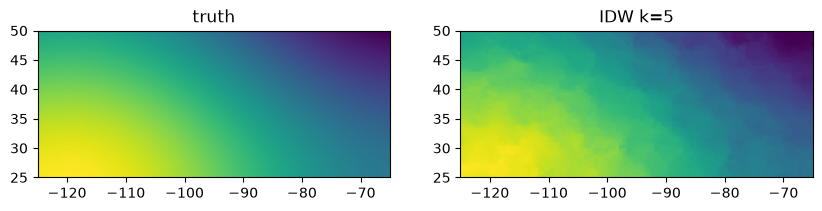

In [14]:
import matplotlib.pyplot as plt

day = 100.0
glat, glon = np.meshgrid(np.linspace(25, 50, 50), np.linspace(-125, -65, 100), indexing="ij")
pred = find_knn_and_predict(lat, lon, t, y, glat.ravel(), glon.ravel(), np.full(glat.size, day),
                         (5,), "regression", 0, 1e2, device="cpu")[5]
truth = np.sin(np.radians(glat) * 4) + np.cos(np.radians(glon) * 3) + np.sin(day / 50)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, img, title in zip(ax, (truth, pred.reshape(glat.shape)), ("truth", "IDW k=5")):
    a.imshow(img, origin="lower", extent=(-125, -65, 25, 50)); a.set_title(title)
plt.show()


# Try on real datasets

In [15]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from torchgeo_bench.coordbench.datasets import (
    load_daily_usa_electric_usage, load_era5_ecmwf, load_chelsa_monthly)

Can also use a subsample

exact kNN is O(N_test * N_train)

In [16]:
def prep(b, target, subsample_N=None, group=None):
    valid = np.where((b.lat >= -60) & np.isfinite(b.tasks[target]))[0]

    num_samples = min(subsample_N, len(valid)) if subsample_N is not None else len(valid)
    idx = rng.choice(valid, num_samples, replace=False)

    lat, lon, t = b.lat[idx], b.lon[idx], b.posix_timestamp[idx]

    if group is None:  # one group per unique location
        group = np.unique(np.c_[lat, lon], axis=0, return_inverse=True)[1].ravel()
    else:
        group = group[idx]

    # random test split for now...
    test_g = rng.choice(np.unique(group), len(np.unique(group)) // 5, replace=False)
    test = np.isin(group, test_g)

    return dict(name=b.name, lat=lat, lon=lon, t=t,
                tasks={target: b.tasks[target][idx]}, test=test)

In [17]:
elec = load_daily_usa_electric_usage(subsample_locations=True)[0]
era5 = load_era5_ecmwf(subsample_locations=True)[0]
chelsa = load_chelsa_monthly(subsample_locations=True)[0]


/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: invalid value encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))


In [18]:
data = (
    [prep(elec, t, group=elec.spatial_aggregation_key[1].to_numpy(), subsample_N=None) for t in elec.tasks]
    + [prep(era5, "t2m", subsample_N=None)]
    + [prep(chelsa, "hurs", subsample_N=None)]
)

In [19]:
KS, CS = (5, 20), (0.0, 1e-20, 1e-18, 1e-16, 1e-15, 1e-14, 1e-13, 1e-12, 1e-10, 0.1, 1.0, 10.0, 100.0, 1000.0)  # c=0 is spatial-only IDW
rows, preds = [], {}
for d in data:
    tr, te = ~d["test"], d["test"]
    for task, y in d["tasks"].items():
        for c in CS:
            p = find_knn_and_predict(d["lat"][tr], d["lon"][tr], d["t"][tr], y[tr],
                                  d["lat"][te], d["lon"][te], d["t"][te], KS, "regression", 0, c, device="cuda")
            for k in KS:
                print(f"{d['name']} {task} k={k} c={c:g}")
                rows.append((d["name"], task, f"idw k={k} c={c:g}", r2_score(y[te], p[k])))
            preds[(d["name"], task, c)] = p[20]

usa_daily_electric_load_2016_from_centroid median k=5 c=0
usa_daily_electric_load_2016_from_centroid median k=20 c=0
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-20
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-20
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-18
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-18
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-16
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-16
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-15
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-15
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-14
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-14
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-13
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-13
usa_daily_electric_load_2016_from_centroid median k=5 c=1e-12
usa_daily_electric_load_2016_from_centroid median k=20 c=1e-12
usa_dail

### See if using time in spatiotemporal IDW beats spatial only IDW (with c=0)

In [20]:
from sklearn.metrics import r2_score

for d in data:
    te = d["test"]
    for task, y in d["tasks"].items():
        print(f"\n{d['name']} - {task}")
        for c in CS:
            p = preds[(d["name"], task, c)]
            print(f"c={c:g}: R²={r2_score(y[te], p):.3f}")


usa_daily_electric_load_2016_from_centroid - median
c=0: R²=0.270
c=1e-20: R²=0.270
c=1e-18: R²=0.270
c=1e-16: R²=0.270
c=1e-15: R²=0.270
c=1e-14: R²=0.258
c=1e-13: R²=0.271
c=1e-12: R²=0.275
c=1e-10: R²=0.282
c=0.1: R²=0.022
c=1: R²=-0.007
c=10: R²=-0.015
c=100: R²=-0.017
c=1000: R²=-0.017

usa_daily_electric_load_2016_from_centroid - median_log
c=0: R²=-0.029
c=1e-20: R²=-0.029
c=1e-18: R²=-0.029
c=1e-16: R²=-0.029
c=1e-15: R²=-0.029
c=1e-14: R²=-0.037
c=1e-13: R²=-0.031
c=1e-12: R²=-0.029
c=1e-10: R²=-0.009
c=0.1: R²=0.056
c=1: R²=-0.030
c=10: R²=-0.054
c=100: R²=-0.063
c=1000: R²=-0.067

era5_ecmwf - t2m
c=0: R²=0.633
c=1e-20: R²=0.633
c=1e-18: R²=0.633
c=1e-16: R²=0.633
c=1e-15: R²=0.633
c=1e-14: R²=0.690
c=1e-13: R²=0.917
c=1e-12: R²=0.947
c=1e-10: R²=0.954
c=0.1: R²=0.920
c=1: R²=0.720
c=10: R²=0.453
c=100: R²=0.256
c=1000: R²=0.177

chelsa - hurs
c=0: R²=0.607
c=1e-20: R²=0.607
c=1e-18: R²=0.607
c=1e-16: R²=0.608
c=1e-15: R²=0.602
c=1e-14: R²=0.597
c=1e-13: R²=0.563
c=1e-12: R

### Compare to Climplicit, TSatCLIP

In [21]:
from torchgeo_bench.coordbench.models import ClimplicitLocationEncoder, TemporalSatCLIPEncoder
from torchgeo_bench.coordbench.probe import linear_probe_score

In [22]:
import os
os.environ["SATCLIP_HOME"] = os.path.expanduser("~/projects/temporal-satclip")
os.environ["CKPT_HOME"] = os.path.expanduser("/projects/bgtj/t_satclip/ckpts/")


In [23]:
encoders = {
    "climplicit": ClimplicitLocationEncoder(device="cuda"),
    "t-satclip": TemporalSatCLIPEncoder("t_satclip-ckpts/tsatclip-doy-1M.ckpt",  # path from conf/model/t_satclip/t_satclip_doy_1M.yaml
                                        model_name="tsatclip/doy", device="cuda"),
}
for d in data:
    for enc_name, enc in encoders.items():
        X = enc.encode(d["lon"], d["lat"], d["t"])
        for task, y in d["tasks"].items():
            score, _, _ = linear_probe_score(X, y, "regression", test_mask=d["test"], device="cuda")
            rows.append((d["name"], task, enc_name, score))

/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


using pretrained moco vit16
using loss function: satclip_loss
using temporal model: True


/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)


## Visualization

In [24]:
import pandas as pd
df = pd.DataFrame(rows, columns=["dataset", "task", "method", "r2"])
print(df.pivot_table(index=["dataset", "task"], columns="method", values="r2").round(3))

method                                                 climplicit  \
dataset                                    task                     
chelsa                                     hurs             0.910   
era5_ecmwf                                 t2m              0.940   
usa_daily_electric_load_2016_from_centroid median           0.062   
                                           median_log       0.165   

method                                                 idw k=20 c=0  \
dataset                                    task                       
chelsa                                     hurs               0.607   
era5_ecmwf                                 t2m                0.633   
usa_daily_electric_load_2016_from_centroid median             0.270   
                                           median_log        -0.029   

method                                                 idw k=20 c=0.1  \
dataset                                    task                         
chelsa      

IndexError: tuple index out of range

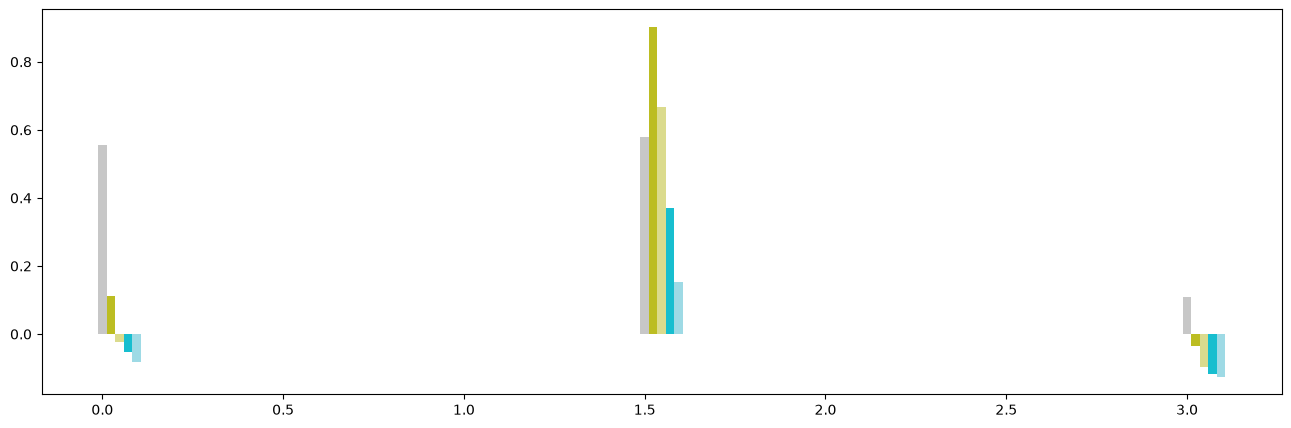

In [25]:
r2 = df.groupby(["dataset", "method"]).r2.mean().unstack()
groups = r2.columns.str.extract(r"(k=\d+)", expand=False).fillna("encoders")
order = sorted(set(groups), key=lambda g: (g == "encoders", int(g[2:]) if g != "encoders" else 0))

colors = plt.get_cmap("tab20").colors

gap = 2  # blank bar slots between method groups
n_slots = len(r2.columns) + gap * (len(order) - 1)
w = 0.8 / n_slots

# More space between datasets
x = np.arange(len(r2)) * 1.5

fig, ax = plt.subplots(figsize=(16, 5))
pos = 0
for g in order:
    for m in r2.columns[groups == g]:
        ax.bar(x + pos * w, r2[m], w, label=m,
               color=colors[r2.columns.get_loc(m)])
        pos += 1
    pos += gap

# Center dataset labels
center = (n_slots - 1) * w / 2
ax.set_xticks(x + center, r2.index)

# Vertical separators between datasets
for i in range(len(x) - 1):
    ax.axvline((x[i] + x[i+1]) / 2 + center,
               color="gray", linestyle="--", alpha=0.5)

ax.set_ylabel("Mean R²")
ax.set_ylim(0, 1)
ax.legend(bbox_to_anchor=(1, 1), loc="upper left", fontsize=8)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()